# Summaries over regions

Many questions ask about a whole region at once. A heat-health plan asks which share of a city
exceeds a temperature and how hot that share is. A water agency asks which share of a catchment lies
above a soil-moisture level and how wet it is there. A forest inventory asks the same of biomass. Each
question names a threshold, but the threshold is often still open, so the answer is a curve, the share
above every threshold with the mean value of that share. A published map of district means then needs
a class of confidence for each district, high, medium or low, according to how well its mean is known.
Here we answer both questions from an ensemble, on simulated fields whose truth we know, comparing the
answers with the usual practice.

## Learning goals

- How the members give a band around the selection curve, the share above each threshold with its mean.
- Why a band from drawing members comes out too narrow for a curve or a block mean.
- Why the curve of the map of means overstates the share above low thresholds and understates it above
  high ones.
- How the law of a block's mean gives a measure of confidence, its relative half-width.
- Why classes from that measure are ordered in error, while classes from the kriging variance barely
  separate the first two.

*How well do we know a summary of a region?*

## The idea

For a threshold $c$, the share of the domain above it and the mean value of that share are

$$T(c) = \frac{1}{|D|} \int_D \mathbf 1\{Z(v) > c\}\, dv, \qquad
G(c) = \frac{\int_D Z(v)\, \mathbf 1\{Z(v) > c\}\, dv}{\int_D \mathbf 1\{Z(v) > c\}\, dv} .$$

Together they form the **selection curve**, known in mining as the grade–tonnage curve. Both depend on
the whole field at once, as the exceedance area does, so each member, a map, gives one curve, the
curves of all the members forming the law of the curve. The **map of means** is smoother than the
field, its values packed towards the centre, so its curve holds too few of the low values a low
threshold excludes and too few of the high values a high threshold selects. This is the support effect.

For a block, a district or any unit of the map, the average of a member over its cells is one possible
block mean per partition, so the members give the law of the block mean. Its **relative half-width**

$$h_B = \frac{q_{0.95}(Z_B) - q_{0.05}(Z_B)}{2\, q_{0.50}(Z_B)}$$

reads as a tolerance, $h_B = 0.15$ saying that the block mean lies within ±15 % of its median with
probability 0.9. The theory Spatialize rests on sets classes of confidence on it, at 0.15 and 0.30, in its
treatment of mineral resources, where the classes are called measured, indicated and inferred. It also
proves that the **kriging variance**, the usual proxy, depends on the variogram and the locations of the
data alone, never on their values.

## Step by step

### A skewed field

The field is a Voronoi block-mark field on the unit square, 30 cells each with a lognormal value, a
positive and skewed variable, read at 350 locations on a 36 × 36 grid.

chosen by the CRPS {'local_interpolator': 'draw', 'p_process': 'voronoi', 'alpha': 0.9}


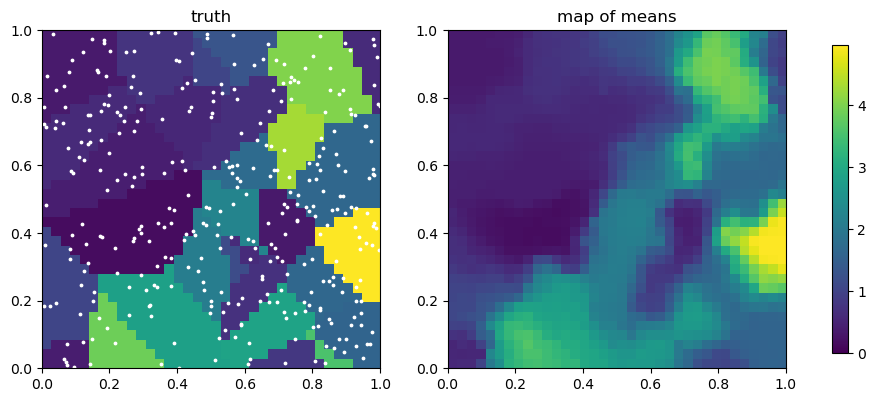

spread of the field 1.39, of the map of means 1.12


In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import spatialize
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", category=RuntimeWarning)

m = 36
grid = (np.arange(m) + 0.5) / m
xi = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)          # maps are [y, x]

def skewed_field(seed, design="uniform"):
    rng = np.random.default_rng(seed)
    nuclei = rng.random((30, 2))
    marks = rng.lognormal(0.0, 0.8, 30)
    value = lambda x: marks[np.argmin(((x[:, None, :] - nuclei[None]) ** 2).sum(-1), axis=1)]
    if design == "uniform":
        points = rng.random((350, 2))
    else:                                   # 150 locations everywhere, 150 more in the central square
        points = np.vstack([rng.random((150, 2)), 0.25 + 0.5 * rng.random((150, 2))])
    return points, value(points), value(xi)

def best_recipe(points, values):
    # the ensemble chosen by the CRPS among drawing decoders, each sample left out in turn
    best = None
    for p_process, decoder in (("voronoi", "draw"), ("voronoi", "wdraw_idw"), ("mondrian", "wdraw_idw"),
                               ("voronoi", "wdraw_sharpidw")):
        options = dict(exponent=[2.0]) if decoder == "wdraw_idw" else {}
        knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, p_process=p_process,
                                         n_partitions=[100], alpha=[0.6, 0.7, 0.8, 0.9, 0.95], k="loo",
                                         scoring="crps", seed=0, **options).best_result(strategy="knee")
        if best is None or knee["decoder_error"] < best[0]:
            best = (knee["decoder_error"], dict(local_interpolator=decoder, p_process=p_process, alpha=knee["alpha"],
                                                **{key: knee[key] for key in options}))
    return best[1]

points, values, truth = skewed_field(0)
recipe = best_recipe(points, values)
members = esi_nongriddata(points, values, xi, n_partitions=300, seed=0, **recipe).esi_samples()
print("chosen by the CRPS", recipe)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, z) in zip(axes, [("truth", truth), ("map of means", members.mean(axis=1))]):
    im = ax.imshow(z.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=0, vmax=np.quantile(truth, 0.99))
    ax.set_title(title)
axes[0].scatter(points[:, 0], points[:, 1], s=3, c="white")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()
print(f"spread of the field {truth.std():.2f}, of the map of means {members.mean(axis=1).std():.2f}")

### The selection curve with a band

Each member gives one curve of the share above the threshold and one of the mean above it, over 22
thresholds. The band holds the middle 90 % of the members' curves at each threshold. The truth's curve and the curve of the map of means are drawn
over it.

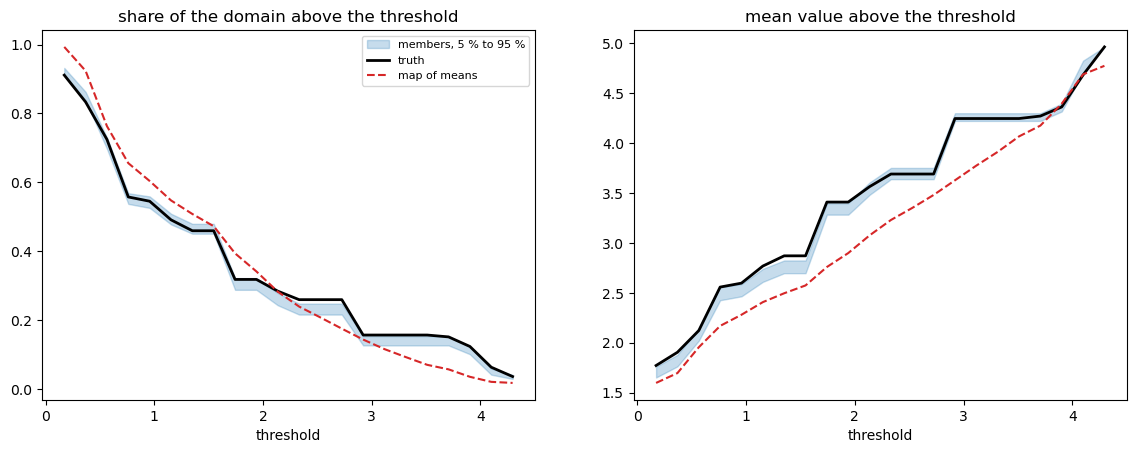

,"thresholds inside the band, of 22","map of means against truth, lowest threshold","map of means against truth, highest threshold"
share,10,0.090,-0.500
mean,11,-0.098,-0.038


In [2]:
thresholds = np.linspace(np.quantile(truth, 0.02), np.quantile(truth, 0.95), 22)

def curves(fields):
    fields = fields if fields.ndim == 2 else fields[:, None]
    above = np.stack([fields > c for c in thresholds])                     # [cut, location, field]
    share = above.mean(axis=1)
    mean_above = (fields[None] * above).sum(axis=1) / np.maximum(above.sum(axis=1), 1)
    return share, np.where(above.sum(axis=1) > 0, mean_above, np.nan)

true_t, true_g = (c[:, 0] for c in curves(truth))
member_t, member_g = curves(members)
mean_t, mean_g = (c[:, 0] for c in curves(members.mean(axis=1)))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (title, tr, mem, mm) in zip(axes, [("share of the domain above the threshold", true_t, member_t, mean_t),
                                           ("mean value above the threshold", true_g, member_g, mean_g)]):
    lo, hi = np.nanquantile(mem, [0.05, 0.95], axis=1)
    ax.fill_between(thresholds, lo, hi, color="C0", alpha=0.25, label="members, 5 % to 95 %")
    ax.plot(thresholds, tr, "k-", lw=2, label="truth")
    ax.plot(thresholds, mm, "C3--", label="map of means")
    ax.set_xlabel("threshold"); ax.set_title(title)
axes[0].legend(fontsize=8)
plt.show()

covered = lambda tr, mem: int(np.sum((np.nanquantile(mem, 0.05, axis=1) <= tr) & (tr <= np.nanquantile(mem, 0.95, axis=1))))
pd.DataFrame({"thresholds inside the band, of 22": {"share": covered(true_t, member_t), "mean": covered(true_g, member_g)},
              "map of means against truth, lowest threshold": {"share": mean_t[0] / true_t[0] - 1, "mean": mean_g[0] / true_g[0] - 1},
              "map of means against truth, highest threshold": {"share": mean_t[-1] / true_t[-1] - 1,
                                                                 "mean": mean_g[-1] / true_g[-1] - 1}}).round(3)

The members' curves lie close together. The true curve runs along the upper edge of their band, inside
it at 10 of 22 thresholds for the share and at 11 for the mean, so the band is too narrow for the
curve. The map of means shows the support effect plainly. At the lowest threshold it gives a share 9 %
larger than the truth, at the highest half of it, with a mean above the threshold below the truth over
the whole range.

### Confidence by block

For the classes the sampling is preferential, as it often is once early results draw attention to one
part of a region. Half of 300 locations cover the field and the other half the central square, a quarter
of the area. The blocks are 3 × 3 cells of the grid, 144 of them, standing for districts or management
units. For each block the members give the law of its mean, from which we read $h_B$. The usual proxy,
the ordinary kriging variance of the block mean, comes from a spherical variogram fitted to the data,
solved exactly on each block.

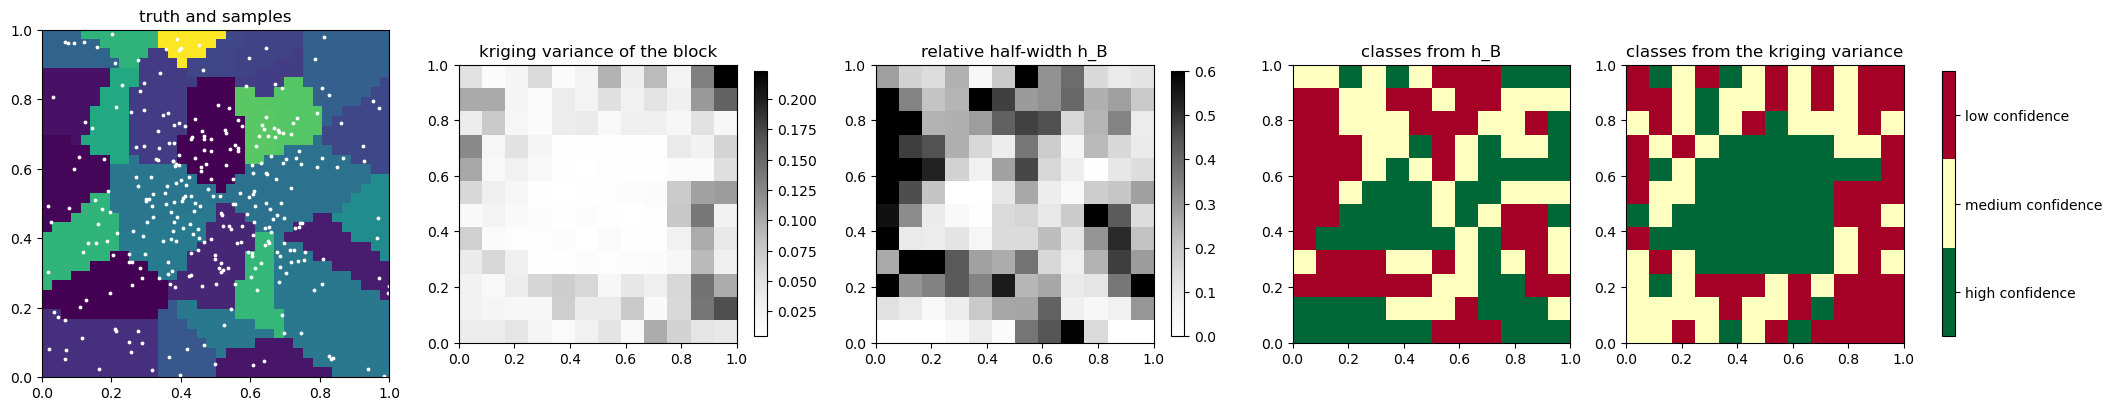

,blocks,"median relative error, law","median relative error, kriging variance",true block inside the 5 % to 95 % band
high confidence,51,0.021,0.072,0.569
medium confidence,44,0.107,0.089,0.773
low confidence,49,0.278,0.192,0.776


In [3]:
points, values, truth = skewed_field(1, design="preferential")
recipe = best_recipe(points, values)
members = esi_nongriddata(points, values, xi, n_partitions=300, seed=0, **recipe).esi_samples()
side = np.arange(m) // 3
block = (side[None, :] + 12 * side[:, None]).ravel()                    # the block of each grid node
n_blocks = 144
block_members = np.stack([members[block == b].mean(axis=0) for b in range(n_blocks)])
true_block = np.array([truth[block == b].mean() for b in range(n_blocks)])
q05, q50, q95 = np.quantile(block_members, [0.05, 0.5, 0.95], axis=1)
half_width = (q95 - q05) / (2 * q50)
relative_error = np.abs(block_members.mean(axis=1) - true_block) / true_block

def spherical(h, c0, c, a):
    return c0 + c * np.where(h < a, 1.5 * h / a - 0.5 * (h / a) ** 3, 1.0)

def block_kriging_variance(points, values):
    i, j = np.triu_indices(len(points), 1)
    dist = np.hypot(*(points[i] - points[j]).T)
    half_sq = 0.5 * (values[i] - values[j]) ** 2
    bins = np.digitize(dist, np.linspace(0, 0.6, 16))
    h = np.array([dist[bins == b].mean() for b in range(1, 16)])
    g = np.array([half_sq[bins == b].mean() for b in range(1, 16)])
    (c0, c, a), _ = curve_fit(spherical, h, g, p0=[0.1 * g.max(), g.max(), 0.2], bounds=([0, 1e-6, 0.01], [np.inf, np.inf, 2]))
    gamma = lambda u, w: np.where((d := np.hypot(*(u[:, None] - w[None]).transpose(2, 0, 1))) > 0, spherical(d, c0, c, a), 0.0)
    n = len(points)
    system = np.ones((n + 1, n + 1)); system[:n, :n] = gamma(points, points); system[n, n] = 0.0
    out = []
    for b in range(n_blocks):
        cells = xi[block == b]
        to_block = gamma(points, cells).mean(axis=1)
        weights = np.linalg.solve(system, np.r_[to_block, 1.0])
        out.append(weights[:n] @ to_block + weights[n] - gamma(cells, cells).mean())
    return np.array(out)

kriging_variance = block_kriging_variance(points, values)

law_category = np.where(half_width <= 0.15, 0, np.where(half_width <= 0.30, 1, 2))
counts = np.bincount(law_category, minlength=3)
order = np.argsort(kriging_variance)                                    # the same counts, smallest variance first
proxy_category = np.empty(n_blocks, int)
proxy_category[order[:counts[0]]], proxy_category[order[counts[0]:counts[:2].sum()]], proxy_category[order[counts[:2].sum():]] = 0, 1, 2

names = ["high confidence", "medium confidence", "low confidence"]
fig, axes = plt.subplots(1, 5, figsize=(26, 4.6))
blockmap = lambda v: v.reshape(12, 12)
axes[0].imshow(truth.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
axes[0].scatter(points[:, 0], points[:, 1], s=3, c="white"); axes[0].set_title("truth and samples")
for ax, (title, v) in zip(axes[1:3], [("kriging variance of the block", kriging_variance),
                                      ("relative half-width h_B", np.minimum(half_width, 0.6))]):
    im = ax.imshow(blockmap(v), origin="lower", extent=(0, 1, 0, 1), cmap="Greys")
    fig.colorbar(im, ax=ax, shrink=0.75); ax.set_title(title)
for ax, (title, v) in zip(axes[3:], [("classes from h_B", law_category), ("classes from the kriging variance", proxy_category)]):
    im = ax.imshow(blockmap(v), origin="lower", extent=(0, 1, 0, 1), cmap=plt.get_cmap("RdYlGn_r", 3), vmin=-0.5, vmax=2.5)
    ax.set_title(title)
cbar = fig.colorbar(im, ax=axes[3:], shrink=0.75, ticks=[0, 1, 2]); cbar.ax.set_yticklabels(names)
plt.show()
pd.DataFrame({"blocks": counts, "median relative error, law": [np.median(relative_error[law_category == k]) for k in range(3)],
              "median relative error, kriging variance": [np.median(relative_error[proxy_category == k]) for k in range(3)],
              "true block inside the 5 % to 95 % band": [np.mean(((q05 <= true_block) & (true_block <= q95))[law_category == k])
                                                         for k in range(3)]},
             index=names).round(3)

The law sorts the blocks by error, the median relative error rising from 0.021 among the blocks of high
confidence to 0.107 and 0.278. The kriging variance, with the same counts, gives 0.072, 0.089 and 0.192,
so its first two classes differ little. Its classes follow the sampling, high confidence over the densely
sampled central square. The classes from $h_B$ follow the values too. A block inside one uniform cell
has high confidence wherever it lies, while a block across a contact has low confidence, as has a block
of low values, whose small median inflates the ratio. The bands themselves contain the true block mean
in 57 % to 78 % of the blocks against a nominal 90 %. The half-widths rank the blocks well while
understating their spread.

### A proxy blind to the values

The kriging variance uses the variogram and the locations of the data, not their values. Multiplying
every value by 50 and adding 1 000, with the variogram held fixed, leaves it unchanged, while the law
of each block moves with the values it averages.

In [4]:
def kriging_variance_fixed_variogram(points, values, c0, c, a):
    gamma = lambda u, w: np.where((d := np.hypot(*(u[:, None] - w[None]).transpose(2, 0, 1))) > 0, spherical(d, c0, c, a), 0.0)
    n = len(points)
    system = np.ones((n + 1, n + 1)); system[:n, :n] = gamma(points, points); system[n, n] = 0.0
    cells = xi[block == 70]
    to_block = gamma(points, cells).mean(axis=1)
    w = np.linalg.solve(system, np.r_[to_block, 1.0])
    return w[:n] @ to_block + w[n] - gamma(cells, cells).mean()

pd.Series({"block kriging variance, the values": kriging_variance_fixed_variogram(points, values, 0.1, 0.5, 0.2),
           "block kriging variance, 50 × values + 1 000": kriging_variance_fixed_variogram(points, 50 * values + 1000, 0.1, 0.5, 0.2)},
          name="one block, the same variogram").to_frame()

,"one block, the same variogram"
"block kriging variance, the values",0.27766
"block kriging variance, 50 × values + 1 000",0.27766


The two variances agree to the last digit. The kriging variance reports where the data lie, never
what they say.

## Pitfalls

- **The curve of the map of means.** It carries the support effect, too large a share above low
  thresholds and too small above high ones. Read the curve with its band from the members.
- **A band from drawing members.** Each location draws its datum on its own, so a curve or a block
  mean, an average over many locations, cancels part of the spread a real field keeps. Here the true
  curve leaves the band at half the thresholds. The block bands hold the truth in at most 78 % of the
  blocks. Read such a band as a lower bound on the uncertainty.
- **Thresholds on $h_B$ taken at face value.** Since the half-widths understate the spread, a block with
  $h_B = 0.15$ is known less well than ±15 %. They still rank the blocks, which a classification needs,
  so set the thresholds by the errors they order.
- **A relative measure on low values.** Dividing by the median sends every block of low values to the
  class of low confidence. For a variable whose low values matter, read the half-width in the units of
  the variable as well.
- **An ensemble chosen for its map.** The curve and the classes are readings of the law, so choose the
  ensemble by the CRPS, as here.

## Try it yourself

1. Sample uniformly instead (`skewed_field(1)`) and compare the two classifications.
2. Use blocks of 6 × 6 cells and watch the half-widths narrow.
3. Read the curve at a threshold between two of the 22 and compare its band with its neighbours'.

## Next

- *Exceedance areas*, for the area above a single limit.
- *Heavy tails*, for variables whose largest values dominate.
- *Choosing a quantile*, for the reading an asymmetric loss selects.
- The documentation's [Error and the choice of a model](https://spatialize.readthedocs.io/en/latest/theory/error.html)
  (theory).